# Reproduction des analyses statistiques du mémoire (tableaux 15, 16 et 17)

**Statut :** notebook de reproduction, ajouté en 2026 lors de la préparation du dépôt.

Les tests de Friedman avec W de Kendall, les tests post-hoc et la décomposition de variance par ANOVA à trois facteurs présentés au chapitre 5 du mémoire ne figurent pas dans les notebooks d'analyse conservés. Ce notebook les **recalcule à partir des G-Mean du dossier `results/`** et compare chaque valeur obtenue à celle publiée.

Les valeurs publiées sont reportées telles qu'elles figurent dans le mémoire. Les écarts éventuels sont signalés, pas corrigés.

In [1]:
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)

RES = Path("../../results")
OUT = RES / "statistiques" / "reproduction"
OUT.mkdir(parents=True, exist_ok=True)

simple = pd.read_csv(RES / "cnn1d_simple_gmean.csv", index_col="projet")
dense = pd.read_csv(RES / "cnn1d_dense_gmean.csv", index_col="projet")
encodeur = pd.read_csv(RES / "transformer_encodeur_gmean.csv", index_col="projet")
multimodal = pd.read_csv(RES / "multimodal_wpdp_cpdp.csv")
hybride_cpdp = multimodal.query("modele == 'Hybride' and contexte == 'CPDP'").set_index("projet")["gmean"]
fullpt_cpdp = multimodal.query("modele == 'Full Pretrained' and contexte == 'CPDP'").set_index("projet")["gmean"]
print(simple.shape, dense.shape, encodeur.shape, hybride_cpdp.shape, fullpt_cpdp.shape)

(11, 6) (11, 6) (11, 6) (10,) (10,)


## 1. Fonctions

- **Friedman** pour k configurations mesurées sur les mêmes N projets, avec la taille d'effet **W de Kendall** = χ² / (N(k − 1)).
- **Wilcoxon** apparié pour deux configurations.
- **Nemenyi** (post-hoc de Friedman) pour situer les paires qui diffèrent.

In [2]:
def friedman(df):
    chi2, p = stats.friedmanchisquare(*[df[c] for c in df.columns])
    n, k = df.shape
    return {"N": n, "test": "Friedman", "statistique": chi2, "p": p, "W_Kendall": chi2 / (n * (k - 1))}


def wilcoxon(a, b):
    r = stats.wilcoxon(a, b)
    return {"N": len(a), "test": "Wilcoxon", "statistique": r.statistic, "p": r.pvalue, "W_Kendall": np.nan}


def effet(w):
    if np.isnan(w):
        return ""
    return "négligeable" if w < 0.1 else "petit" if w < 0.3 else "modéré" if w < 0.5 else "grand"


## 2. Tableau 15 : tests de Friedman et de Wilcoxon

Chaque ligne reprend une comparaison du tableau 15 du mémoire (et, pour la dernière, du texte de la section 5.2.4). Les données utilisées pour chaque ligne sont précisées dans la colonne `donnees`.

In [3]:
S, D, E = simple, dense, encodeur
mm = hybride_cpdp.index  # 10 projets disposant de code source (sans Ivy)

lignes = [
    ("SG vs SV vs SR", "WPDP", "CNN1D simple", friedman(S[["SG_WPDP", "SV_WPDP", "SR_WPDP"]]), (0.727, 0.695, 0.033)),
    ("SG vs SV vs SR", "CPDP", "CNN1D simple", friedman(S[["SG_CPDP", "SV_CPDP", "SR_CPDP"]]), (2.182, 0.336, 0.099)),
    ("CNN1D simple vs dense", "WPDP", "SG", wilcoxon(S["SG_WPDP"], D["SG_WPDP"]), (28.0, 0.700, None)),
    ("CNN1D simple vs dense", "CPDP", "SG", wilcoxon(S["SG_CPDP"], D["SG_CPDP"]), (23.0, 0.413, None)),
    ("SMOTE vs sous-éch. vs outliers", "WPDP", "Transformer encodeur, 11 projets",
     friedman(E[["WPDP_SMOTE", "WPDP_sous_ech", "WPDP_sous_ech_outliers"]]), (2.600, 0.273, 0.130)),
    ("CNN1D vs Transformer encodeur", "CPDP", "CNN1D simple SG ; encodeur SMOTE",
     wilcoxon(S["SG_CPDP"], E["CPDP_SMOTE"]), (6.0, 0.014, None)),
    ("CNN1D vs encodeur vs Hybride", "CPDP", "SG ; encodeur SMOTE ; 10 projets",
     friedman(pd.DataFrame({"cnn1d": S.loc[mm, "SG_CPDP"], "encodeur": E.loc[mm, "CPDP_SMOTE"], "hybride": hybride_cpdp})),
     (5.600, 0.061, 0.280)),
    ("CNN1D vs encodeur vs Full Pretrained", "CPDP", "SG ; encodeur SMOTE ; 10 projets",
     friedman(pd.DataFrame({"cnn1d": S.loc[mm, "SG_CPDP"], "encodeur": E.loc[mm, "CPDP_SMOTE"], "full_pretrained": fullpt_cpdp[mm]})),
     (6.200, 0.045, 0.310)),
]

rows = []
for comp, ctx, donnees, r, (s_pub, p_pub, w_pub) in lignes:
    rows.append({
        "comparaison": comp, "contexte": ctx, "donnees": donnees, "N": r["N"], "test": r["test"],
        "statistique": round(r["statistique"], 3), "p": round(r["p"], 3),
        "W_Kendall": round(r["W_Kendall"], 3) if not np.isnan(r["W_Kendall"]) else np.nan,
        "effet": effet(r["W_Kendall"]),
        "stat_memoire": s_pub, "p_memoire": p_pub, "W_memoire": w_pub,
        "concorde": abs(r["statistique"] - s_pub) < 0.01 and abs(r["p"] - p_pub) < 0.002,
    })
tableau15 = pd.DataFrame(rows)
tableau15.to_csv(OUT / "tableau15_reproduction.csv", index=False)
tableau15

,comparaison,contexte,donnees,N,test,statistique,p,W_Kendall,effet,stat_memoire,p_memoire,W_memoire,concorde
0,SG vs SV vs SR,WPDP,CNN1D simple,11,Friedman,0.727,0.695,0.033,négligeable,0.727,0.695,0.033,True
1,SG vs SV vs SR,CPDP,CNN1D simple,11,Friedman,2.182,0.336,0.099,négligeable,2.182,0.336,0.099,True
2,CNN1D simple vs dense,WPDP,SG,11,Wilcoxon,28.000,0.700,NaN,,28.000,0.700,NaN,True
3,CNN1D simple vs dense,CPDP,SG,11,Wilcoxon,23.000,0.413,NaN,,23.000,0.413,NaN,True
4,SMOTE vs sous-éch. vs outliers,WPDP,"Transformer encodeur, 11 projets",11,Friedman,2.364,0.307,0.107,petit,2.600,0.273,0.130,False
5,CNN1D vs Transformer encodeur,CPDP,CNN1D simple SG ; encodeur SMOTE,11,Wilcoxon,6.000,0.014,NaN,,6.000,0.014,NaN,True
6,CNN1D vs encodeur vs Hybride,CPDP,SG ; encodeur SMOTE ; 10 projets,10,Friedman,7.800,0.020,0.390,modéré,5.600,0.061,0.280,False
7,CNN1D vs encodeur vs Full Pretrained,CPDP,SG ; encodeur SMOTE ; 10 projets,10,Friedman,5.400,0.067,0.270,petit,6.200,0.045,0.310,False


**Lecture.** Cinq des sept lignes du tableau 15 sont reproduites à l'identique à partir des fichiers de `results/`. Les deux autres, et la comparaison avec le Full Pretrained citée dans le texte de la section 5.2.4, ne le sont pas.

- **Équilibrage du Transformer encodeur (WPDP).** Le mémoire indique N = 10 et χ² = 2,600. Sur les 11 projets, on obtient χ² = 2,364. Aucun retrait d'un seul projet ne redonne 2,600 (voir la cellule suivante). La série utilisée dans le mémoire n'a donc pas pu être identifiée.
- **Comparaisons avec les modèles multimodaux.** Avec les G-Mean multimodales de `results/multimodal_wpdp_cpdp.csv`, recalculées comme √(sensibilité × spécificité), on obtient :
  - avec l'Hybride : χ² = 7,800 (p = 0,020), la valeur retenue dans l'article WSSE 2026, alors que le mémoire indique 5,600 (p = 0,061) ;
  - avec le Full Pretrained : χ² = 5,400 (p = 0,067), alors que le mémoire indique 6,200 (p = 0,045).

  Le mémoire s'appuyait sur les valeurs de son tableau 12, qui comportent des erreurs de transcription. La conclusion change pour le Full Pretrained : la différence n'est plus significative au seuil de 5 %.

In [4]:
T = E[["WPDP_SMOTE", "WPDP_sous_ech", "WPDP_sous_ech_outliers"]]
pd.DataFrame([{"projet_retire": p, **friedman(T.drop(p))} for p in T.index]).round(3)

,projet_retire,N,test,statistique,p,W_Kendall
0,ant,10,Friedman,1.4,0.497,0.07
1,camel,10,Friedman,4.2,0.122,0.21
2,ivy,10,Friedman,4.2,0.122,0.21
3,jedit,10,Friedman,3.8,0.150,0.19
4,log4j,10,Friedman,2.4,0.301,0.12
5,lucene,10,Friedman,1.4,0.497,0.07
6,poi,10,Friedman,1.8,0.407,0.09
7,synapse,10,Friedman,1.4,0.497,0.07
8,velocity,10,Friedman,1.8,0.407,0.09
9,xalan,10,Friedman,1.8,0.407,0.09


## 3. Post-hoc de Nemenyi

Le test de Friedman entre CNN1D simple, Transformer encodeur et Hybride (CPDP) est significatif (p = 0,020). Le test de Nemenyi indique quelles paires diffèrent. Le diagramme de différence critique place chaque modèle selon son rang moyen ; les modèles reliés par un trait ne diffèrent pas significativement.

In [5]:
trio = pd.DataFrame({"CNN1D simple": S.loc[mm, "SG_CPDP"], "Transformer encodeur": E.loc[mm, "CPDP_SMOTE"],
                     "Hybride": hybride_cpdp})
rangs = trio.rank(axis=1, ascending=False).mean().sort_values()
print("Rangs moyens (1 = meilleur) :")
print(rangs.round(2))
nemenyi = sp.posthoc_nemenyi_friedman(trio.reset_index(drop=True))
nemenyi.to_csv(OUT / "nemenyi_cnn1d_encodeur_hybride_cpdp.csv")
nemenyi.round(3)

Rangs moyens (1 = meilleur) :
CNN1D simple            1.3
Transformer encodeur    2.2
Hybride                 2.5
dtype: float64


,CNN1D simple,Transformer encodeur,Hybride
CNN1D simple,1.000,0.109,0.02
Transformer encodeur,0.109,1.000,0.78
Hybride,0.020,0.780,1.00


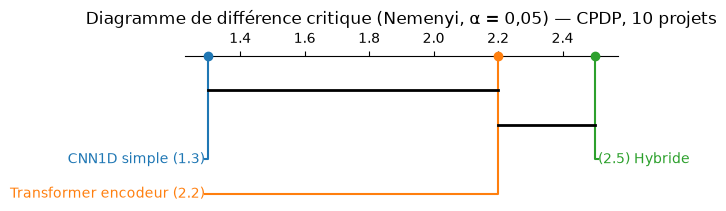

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.2))
sp.critical_difference_diagram(rangs, nemenyi, ax=ax)
ax.set_title("Diagramme de différence critique (Nemenyi, α = 0,05) — CPDP, 10 projets")
plt.tight_layout()
fig.savefig(RES / "statistiques" / "figures" / "nemenyi_diagramme_difference_critique.png", dpi=150)
plt.show()

**Lecture.** Le CNN1D simple obtient le meilleur rang moyen (1,3). Seule la paire CNN1D simple – Hybride diffère significativement (Nemenyi, p = 0,020). L'écart entre CNN1D et Transformer encodeur (p = 0,109) et celui entre encodeur et Hybride (p = 0,780) ne le sont pas.

## 4. Tableaux 16 et 17 : ANOVA à trois facteurs

Facteurs : **projet** (11 niveaux), **standardisation** (SG, SV, SR) et **architecture** (CNN1D simple ou dense), soit 66 observations par contexte. Le plan est équilibré et sans réplication. Le modèle comprend les effets principaux et les interactions d'ordre 2 ; l'interaction d'ordre 3 sert de terme résiduel.

In [7]:
long = []
for archi, df in [("simple", S), ("dense", D)]:
    for ctx in ["WPDP", "CPDP"]:
        for std in ["SG", "SV", "SR"]:
            for projet, g in df[f"{std}_{ctx}"].items():
                long.append({"projet": projet, "standardisation": std, "architecture": archi, "contexte": ctx, "gmean": g})
long = pd.DataFrame(long)


def anova3(ctx):
    d = long[long.contexte == ctx]
    m = smf.ols("gmean ~ C(projet) + C(standardisation) + C(architecture)"
                " + C(projet):C(standardisation) + C(projet):C(architecture)"
                " + C(standardisation):C(architecture)", data=d).fit()
    a = sm.stats.anova_lm(m, typ=1)
    a.index = ["Projet", "Standardisation", "Architecture", "Projet × Standardisation",
               "Projet × Architecture", "Standardisation × Architecture", "Résiduelle"]
    a = a.rename(columns={"sum_sq": "SS", "df": "ddl", "mean_sq": "MS", "PR(>F)": "p"})
    a["eta2_%"] = 100 * a["SS"] / a["SS"].sum()
    a.loc["Total"] = [a["ddl"].sum(), a["SS"].sum(), np.nan, np.nan, np.nan, 100.0]
    return a[["SS", "ddl", "MS", "F", "p", "eta2_%"]]


memoire = {
    "WPDP": {"Projet": 77.0, "Standardisation": 0.1, "Architecture": 0.4, "Projet × Standardisation": 11.7,
             "Projet × Architecture": 4.5, "Standardisation × Architecture": 0.3, "Résiduelle": 6.0, "Total": 100.0},
    "CPDP": {"Projet": 60.3, "Standardisation": 1.0, "Architecture": 1.2, "Projet × Standardisation": 18.2,
             "Projet × Architecture": 8.4, "Standardisation × Architecture": 0.4, "Résiduelle": 10.7, "Total": 100.0},
}
ss_total_memoire = {"WPDP": 3148.6, "CPDP": 3157.0}

tables = {}
for ctx in ["WPDP", "CPDP"]:
    t = anova3(ctx)
    t["eta2_%_memoire"] = pd.Series(memoire[ctx])
    tables[ctx] = t
    t.round(3).to_csv(OUT / f"anova_trois_facteurs_{ctx}.csv")
    print(f"=== {ctx} : SS total recalculée = {t.loc['Total', 'SS']:.1f} (mémoire : {ss_total_memoire[ctx]})")
tables["WPDP"].round(3)

=== WPDP : SS total recalculée = 3410.1 (mémoire : 3148.6)
=== CPDP : SS total recalculée = 3187.5 (mémoire : 3157.0)


,SS,ddl,MS,F,p,eta2_%,eta2_%_memoire
Projet,2636.420,10.0,263.642,24.265,0.000,77.313,77.0
Standardisation,0.736,2.0,0.368,0.034,0.967,0.022,0.1
Architecture,18.275,1.0,18.275,1.682,0.209,0.536,0.4
Projet × Standardisation,322.575,20.0,16.129,1.484,0.192,9.459,11.7
Projet × Architecture,196.229,10.0,19.623,1.806,0.125,5.754,4.5
Standardisation × Architecture,18.542,2.0,9.271,0.853,0.441,0.544,0.3
Résiduelle,217.303,20.0,10.865,NaN,NaN,6.372,6.0
Total,3410.081,65.0,NaN,NaN,NaN,100.000,100.0


In [8]:
tables["CPDP"].round(3)

,SS,ddl,MS,F,p,eta2_%,eta2_%_memoire
Projet,1906.088,10.0,190.609,11.004,0.000,59.799,60.3
Standardisation,29.711,2.0,14.856,0.858,0.439,0.932,1.0
Architecture,39.332,1.0,39.332,2.271,0.147,1.234,1.2
Projet × Standardisation,584.612,20.0,29.231,1.687,0.125,18.341,18.2
Projet × Architecture,269.218,10.0,26.922,1.554,0.192,8.446,8.4
Standardisation × Architecture,12.079,2.0,6.039,0.349,0.710,0.379,0.4
Résiduelle,346.443,20.0,17.322,NaN,NaN,10.869,10.7
Total,3187.482,65.0,NaN,NaN,NaN,100.000,100.0


**Lecture.** La structure de la décomposition est retrouvée dans les deux contextes :

- le facteur **projet** domine (environ 77 % de la variance en WPDP, 60 % en CPDP) ;
- la standardisation et l'architecture pèsent chacune moins de 2 % ;
- les interactions projet × méthode augmentent en CPDP.

- **CPDP (tableau 17)** : reproduit à quelques dixièmes de point près (projet 59,8 % contre 60,3 % ; somme des carrés totale 3 187 contre 3 157).
- **WPDP (tableau 16)** : la structure est la même, mais les valeurs s'écartent davantage (somme des carrés totale 3 410 contre 3 149 ; projet × standardisation 9,5 % contre 11,7 %). Le tableau 16 a probablement été calculé sur une version légèrement différente des G-Mean WPDP, antérieure aux fichiers conservés dans `results/`.

Les conclusions du mémoire ne changent pas : le projet explique l'essentiel de la variance, et les choix méthodologiques n'ont pas d'effet significatif.

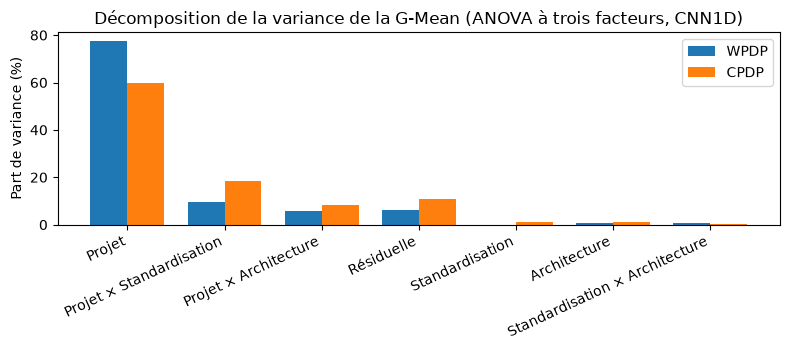

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sources = ["Projet", "Projet × Standardisation", "Projet × Architecture", "Résiduelle",
           "Standardisation", "Architecture", "Standardisation × Architecture"]
x = np.arange(len(sources))
for i, ctx in enumerate(["WPDP", "CPDP"]):
    ax.bar(x + (i - 0.5) * 0.38, tables[ctx].loc[sources, "eta2_%"], width=0.38, label=ctx)
ax.set_xticks(x, sources, rotation=25, ha="right")
ax.set_ylabel("Part de variance (%)")
ax.set_title("Décomposition de la variance de la G-Mean (ANOVA à trois facteurs, CNN1D)")
ax.legend()
plt.tight_layout()
fig.savefig(RES / "statistiques" / "figures" / "anova_decomposition_variance.png", dpi=150)
plt.show()

## 5. Récapitulatif

| Analyse | Reproduite à l'identique | Écart |
|---|---|---|
| Friedman, standardisation (WPDP, CPDP) | oui | — |
| Wilcoxon, CNN1D simple contre dense (WPDP, CPDP) | oui | — |
| Wilcoxon, CNN1D contre Transformer encodeur (CPDP) | oui | — |
| Friedman, équilibrage du Transformer (WPDP) | non | série de 10 projets non identifiée |
| Friedman avec Hybride / Full Pretrained (CPDP) | non | G-Mean multimodales du tableau 12 mal transcrites ; valeurs recalculées : 7,800 et 5,400 |
| Post-hoc de Nemenyi (CNN1D, encodeur, Hybride) | ajouté | seule la paire CNN1D – Hybride est significative (p = 0,020) |
| ANOVA à trois facteurs, CPDP (tableau 17) | à quelques dixièmes près | — |
| ANOVA à trois facteurs, WPDP (tableau 16) | en structure | sommes des carrés différentes (3 410 contre 3 149) |

Les fichiers CSV produits sont dans `results/statistiques/reproduction/` ; les figures, dans `results/statistiques/figures/`.